# 06-T800状态参数


## 1. 本课目标：nq、nv、nu 与 qpos、qvel、ctrl

本篇对应《具身智能机器人实战》第 06 节《T800 状态参数》。上一节观察部件的空间位置，本节认识描述机器人姿态、速度以及控制输入所需的参数。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/06_T800状态参数.pptx` 全部 3 页：第 1 页列出本课参数，第 2 页用机器人和电机图解释 `nq、nv、nu`，第 3 页为品牌结束页。

课件没有展示代码或 T800 的具体参数值。下文先整理图中的概念，再把数组布局与读取方法标为“工程补充”。未转录配套视频，也未读取网盘中的 `code.zip`。


## 2. 课件中的三种数量

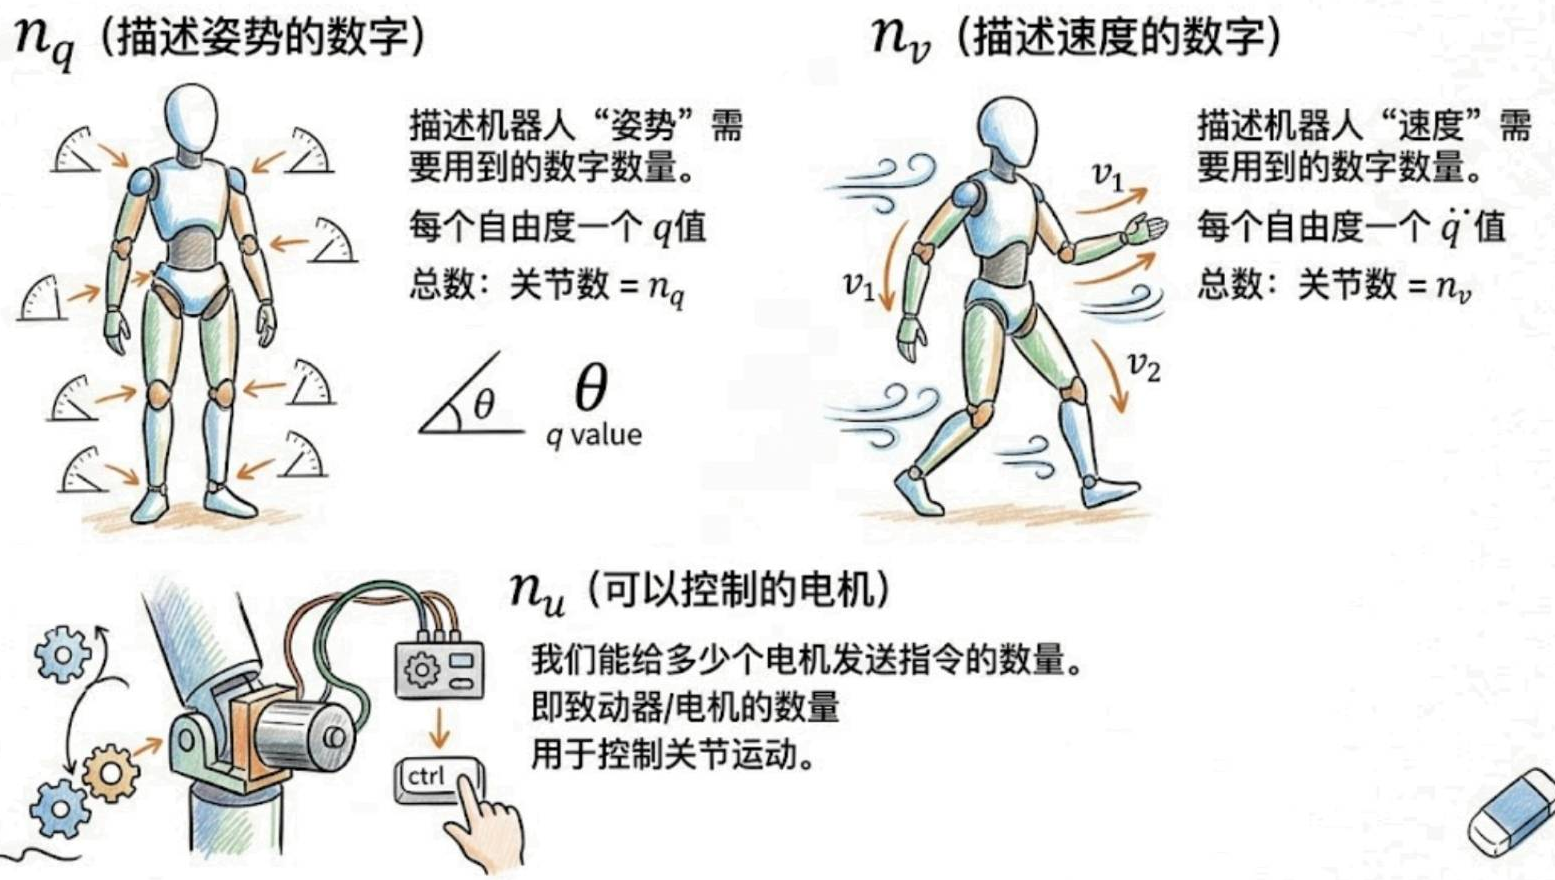

*原课件第 2 页，裁取 `nq、nv、nu` 的教学图。图中“关节数等于 nq、nv”的简化表述需要结合下文条件理解。*

### 2.1 nq：描述姿态需要多少个数字

课件用关节角度说明 `q`：要描述机器人当前怎样摆放，需要记录相应的位置参数，`nq` 表示这些参数的数量。

对于单轴转动关节，一个关节角就能描述该关节的位置。但机器人整体在世界中的位置和朝向也需要描述，使用浮动基座时还要计入这些坐标。

### 2.2 nv：描述速度需要多少个数字

课件进一步用运动中的机器人说明速度：同一个姿态可以对应不同的运动速度，关节当前在哪里与它运动得多快是不同的信息。`nv` 表示速度自由度的数量。

单轴转动关节对应一个角速度。基座也有自身的平移和转动速度，因此不能只统计受电机驱动的关节。

### 2.3 nu：能发送多少路控制输入

课件把 `nu` 类比为“可以控制的电机数量”，用于说明能向多少个驱动器发送指令。在 MuJoCo 中，它准确对应模型中的执行器数量，也就是控制数组的长度。

**工程补充：图中等式的适用条件。**固定基座且每个关节都是单自由度的 hinge（转动）或 slide（滑动）关节时，可以有 `njnt = nq = nv`。浮动基座或球关节会改变这种关系。执行器是另一类对象，`nu` 也不能普遍按关节数推算。


## 3. 工程补充：数量对应的实际数组

`nq、nv、nu` 属于模型的维数信息，实际数值存放在 `MjData` 的数组中：

| 模型参数 | 对应数组 | 含义与长度 |
|---|---|---|
| `model.nq` | `data.qpos` | 广义位置坐标，长度为 `nq` |
| `model.nv` | `data.qvel` | 广义速度，长度为 `nv` |
| `model.nu` | `data.ctrl` | 发给执行器的控制输入，长度为 `nu` |

`qpos` 可以包含关节角、平移和表示旋转的四元数。它与上一节的 `data.xpos` 含义不同：`xpos` 保存各 body 原点的世界位置，`qpos` 则按关节类型组织广义位置坐标。

对于单轴转动关节，位置单位为弧度，速度单位为弧度每秒。四元数部分有 4 个分量，而相应角速度只有 3 个分量，因此不能普遍把 `qvel` 当成对每个 `qpos` 元素直接求导后得到的同长度数组。

`ctrl` 保存控制指令。它的物理含义取决于执行器配置，例如 motor 使用力或力矩输入，position 执行器使用目标位置输入。读取 `ctrl` 不能直接当成读取实际测得的关节力矩，也不能把给 `ctrl` 赋值理解为立即修改关节角。

### 3.1 T800 为什么是 32、31、25

沿用前几篇核对的官方模型提交 `335c60e88772c26c7852d0abd6b3c7439037dd8f`。这个版本有 1 个浮动基座自由关节、25 个单轴转动关节，以及 25 个 motor 执行器。

- `nq = 7 + 25 = 32`：基座用 3 个位置坐标和 4 个四元数分量，其他关节各用 1 个角度。
- `nv = 6 + 25 = 31`：基座有 3 个平移速度和 3 个转动速度，其他关节各用 1 个角速度。
- `nu = 25`：模型定义了 25 个执行器控制输入。

四元数多用一个分量表示三维旋转，旋转本身仍是 3 个自由度。这也是此处 `nq` 比 `nv` 多 1 的原因。该模型的 `njnt` 为 26，进一步说明关节对象数与这三个维数各有含义。

### 3.2 本版本的数组布局

下表是这个模型编译后的顺序，切片使用 Python 的左闭右开规则：

| 数组片段 | 内容 |
|---|---|
| `qpos[0:3]` | 浮动基座的世界位置 `(x, y, z)` |
| `qpos[3:7]` | 浮动基座朝向四元数 `(w, x, y, z)` |
| `qpos[7:]` | 25 个转动关节的位置 |
| `qvel[0:6]` | 浮动基座的 3 个平移速度与 3 个转动速度 |
| `qvel[6:]` | 25 个转动关节的速度 |
| `ctrl[:]` | 按执行器顺序排列的 25 路控制输入 |

这组数量和切片是已注明模型版本的核对结果，不是课件给出的固定常量。更换模型后应重新检查。

### 3.3 同一个关节在不同数组中的下标

第 04 篇查询过的右肩俯仰关节名为 `J18_SHOULDER_PITCH_R`。本版本中，它的 joint ID 为 19，但对应 `qpos` 下标是 25，`qvel` 下标是 24，关联 motor 的 `ctrl` 下标是 18。

`model.jnt_qposadr[joint_id]` 给出关节在 `qpos` 中的起始下标，`model.jnt_dofadr[joint_id]` 给出它在 `qvel` 中的起始下标。执行器则按自己的名称查询 ID。

> 不能把 joint ID 同时用作 `qpos、qvel、ctrl` 的下标。浮动基座占用的元素数量不同，执行器的排列也独立于关节排列。


## 4. 工程补充：读取 T800 初始状态

沿用第 03～05 篇的 `t800-load` 练习目录、官方模型与 `.venv`，新建 `inspect_state.py`。这里查询的右肩是单轴转动关节，只有一个位置值和一个速度值，因而可以使用起始下标读取标量。

```python
import argparse
from pathlib import Path

import mujoco
import numpy as np

parser = argparse.ArgumentParser(description="读取 T800 状态参数")
parser.add_argument(
    "--model", type=Path,
    default=Path(__file__).resolve().parent
    / "engineai_robotics_native_sdk/assets/resource/t800.xml",
)
args = parser.parse_args()
model = mujoco.MjModel.from_xml_path(str(args.model.expanduser().resolve()))
data = mujoco.MjData(model)
mujoco.mj_forward(model, data)

joint_id = model.joint("J18_SHOULDER_PITCH_R").id
qpos_index = int(model.jnt_qposadr[joint_id])
qvel_index = int(model.jnt_dofadr[joint_id])
actuator_id = model.actuator("motor_J18_SHOULDER_PITCH_R").id

np.set_printoptions(precision=5, suppress=True)
print(f"nq={model.nq}, nv={model.nv}, nu={model.nu}")
print("shapes:", data.qpos.shape, data.qvel.shape, data.ctrl.shape)
print("base_qpos:", data.qpos[:7])
print("base_qvel:", data.qvel[:6])
print("indices:", joint_id, qpos_index, qvel_index, actuator_id)
print("shoulder_qpos:", data.qpos[qpos_index])
print("shoulder_qvel:", data.qvel[qvel_index])
print("shoulder_ctrl:", data.ctrl[actuator_id])
```

在 `t800-load` 目录的 PowerShell 中执行：

```powershell
.\.venv\Scripts\python.exe inspect_state.py
```

模型位于其他目录时，可以通过 `--model` 指定场景入口的完整路径。`resolve()` 将入口转换为绝对路径，XML 引用的网格和其他资源仍需保留原来的目录结构。

本篇在 MuJoCo 3.4.0 中实际运行脚本，读取到：

| 检查项 | 本次结果 |
|---|---|
| 维数 | `nq=32, nv=31, nu=25` |
| 三个数组的形状 | `(32,)`、`(31,)`、`(25,)` |
| 基座初始 `qpos[:7]` | `[0, 0, 1.03, 1, 0, 0, 0]` |
| 基座初始 `qvel[:6]` | 6 个 `0` |
| `indices`，依次为 joint ID、位置下标、速度下标、执行器 ID | `19, 25, 24, 18` |
| 右肩位置、速度、控制输入 | 分别为 `0.0`、`0.0`、`0.0` |

初始基座位置为 `(0, 0, 1.03)`，朝向四元数为 `(1, 0, 0, 0)`。零速度和零控制输入来自本次初始化，并不说明机器人能够保持站立。

脚本调用 `mj_forward()` 更新当前状态对应的派生数据，没有调用 `mj_step()`，因此没有推进仿真时间。本节只读取状态，仿真主循环在下一节展开。


## 5. 本课检查与补充参考

完成本节，应能说明 `nq、nv、nu` 分别决定哪个数组的长度，解释浮动基座为什么使 `nq` 与 `nv` 不同，并按名称及地址字段找到关节状态和对应执行器输入。

本篇补充脚本已在官方 T800 模型上运行，核对数组维数、基座布局及右肩下标与初始值，没有验证站立控制或真实硬件。

- [本篇版本的 T800 模型入口与浮动基座](https://github.com/engineai-robotics/engineai_robotics_native_sdk/blob/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/robot/t800/xml/serial_t800.xml)。
- [同版本的执行器配置](https://github.com/engineai-robotics/engineai_robotics_native_sdk/blob/335c60e88772c26c7852d0abd6b3c7439037dd8f/assets/resource/robot/t800/xml/serial_actuators.xml)。
- [MuJoCo 3.4.0：mjModel 的维数与关节地址字段](https://mujoco.readthedocs.io/en/3.4.0/APIreference/APItypes.html#mjmodel)。
- [MuJoCo 3.4.0：mjData 的状态与控制数组](https://mujoco.readthedocs.io/en/3.4.0/APIreference/APItypes.html#mjdata)。
- [MuJoCo 3.4.0：关节类型与自由度](https://mujoco.readthedocs.io/en/3.4.0/XMLreference.html#body-joint)。
